## Standard Errors and the Central Limit Theorem

### Learning Goals
* Understand what a standard error represents.
* Demonstrate the Central Limit Theorem (CLT) using simulation across varying sample sizes.
* Recognize the assumptions, context-dependence, and limitations of the CLT.

---

### 1. Simulating Sample Means and the CLT

The Central Limit Theorem states that as the sample size $n$ increases, the distribution of the sample mean $\bar{X}$ approaches a Normal distribution, *regardless* of the underlying population's shape (provided the population variance is finite). 

Notice how the distribution of sample means transforms from skewed to bell-shaped as $n$ grows, even when starting from a heavily skewed exponential population:

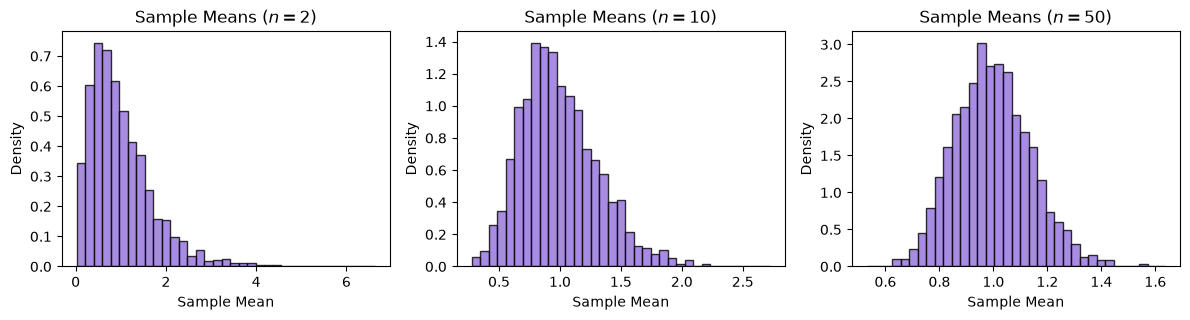

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(202)
# A strongly right-skewed population (Exponential)
population = rng.exponential(scale=1.0, size=200_000)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, n in zip(axes, [2, 10, 50]):
    means = [rng.choice(population, size=n, replace=True).mean() for _ in range(2500)]
    ax.hist(means, bins=35, density=True, color='mediumpurple', edgecolor='black', alpha=0.8)
    ax.set_title(f"Sample Means ($n={n}$)")
    ax.set_xlabel("Sample Mean")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

### 2. Standard Error of a Mean

The **standard error ($SE$)** measures the variability or precision of a sample statistic (like the sample mean). When the population standard deviation $\sigma$ is unknown, we estimate the standard error using the sample standard deviation $s$:
$$
\text{SE}(\bar{x}) = \frac{s}{\sqrt{n}}
$$

In [2]:
# Calculate standard error from a sample
sample = np.array([8, 10, 9, 11, 7, 12, 10, 9])
s = sample.std(ddof=1)
n = len(sample)
se = s / np.sqrt(n)

print(f"Sample Size (n): {n}")
print(f"Sample SD (s): {s:.4f}")
print(f"Estimated Standard Error: {se:.4f}")

Sample Size (n): 8
Sample SD (s): 1.6036
Estimated Standard Error: 0.5669


### Key Idea & Cautions

> **Core Principle:** The CLT states that the *distribution of properly standardized sample means* becomes approximately normal as sample size grows. **It does not say the raw data become normal.**

* **Cautions & Limitations:** 
  * **Dependence:** If observations are correlated (e.g., time-series data), the standard error formula changes.
  * **Heavy Tails / Extreme Skewness:** Populations with infinite variance (e.g., Cauchy distributions) violate CLT assumptions, requiring much larger samples or alternative tools.
  * **Sample Size Context:** A sample size of $n=30$ is a helpful rule of thumb, but highly skewed or outlier-prone data may require much larger samples for the normal approximation to hold.

---

### Exercises

Try each problem before running the verification code below:

1. If a sample has a standard deviation $s = 12$ and a sample size $n = 36$, calculate the estimated standard error.
2. Explain why stating "the data become normal" is a misconception of the Central Limit Theorem.
3. How does dependence between observations affect the standard deviation of sample means?

In [3]:
# --- Exercise Verification ---
print("=== Exercise Solutions & Checks ===")

# 1. Standard Error Calculation
s_ex1 = 12
n_ex1 = 36
se_ex1 = s_ex1 / np.sqrt(n_ex1)
print(f"1. Estimated Standard Error: {se_ex1:.2f}")

print("\n2. Why 'Data Become Normal' is False:")
print("   - The CLT governs the distribution of **sample statistics** (like the mean),")
print("     not the underlying raw data points in the population.")

print("\n3. Effect of Observation Dependence:")
print("   - Positive correlation (dependence) between observations reduces the effective")
print("     sample size, leading to an underestimation of the standard error if independence is assumed.")

=== Exercise Solutions & Checks ===
1. Estimated Standard Error: 2.00

2. Why 'Data Become Normal' is False:
   - The CLT governs the distribution of **sample statistics** (like the mean),
     not the underlying raw data points in the population.

3. Effect of Observation Dependence:
   - Positive correlation (dependence) between observations reduces the effective
     sample size, leading to an underestimation of the standard error if independence is assumed.
